<a href="https://colab.research.google.com/github/chinmayee5599/Regime-Aware-AI-Post-Processing-of-Monsoon-Rainfall-Forecast/blob/main/regime-aware-monsoon-rainfall.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving data_stream-oper_stepType-accum.nc to data_stream-oper_stepType-accum.nc
Saving data_stream-oper_stepType-avg.nc to data_stream-oper_stepType-avg.nc
Saving data_stream-oper_stepType-instant.nc to data_stream-oper_stepType-instant.nc
Saving data_stream-oper_stepType-max.nc to data_stream-oper_stepType-max.nc


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'data_stream-oper_stepType-max.nc', '1d85d9c3713dce953bedb3b096a85ee9.zip', 'data_stream-oper_stepType-instant.nc', 'data_stream-oper_stepType-accum.nc', 'data_stream-oper_stepType-avg.nc', 'sample_data']


In [ ]:
import xarray as xr

file = "/content/data_stream-oper_stepType-accum.nc"

ds = xr.open_dataset(file)

print(ds)

<xarray.Dataset> Size: 6MB
Dimensions:     (valid_time: 976, latitude: 30, longitude: 24)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8kB 2023-06-01 ... 2024-09-30T18:...
  * latitude    (latitude) float64 240B 16.25 16.0 15.75 15.5 ... 9.5 9.25 9.0
  * longitude   (longitude) float64 192B 74.0 74.25 74.5 ... 79.25 79.5 79.75
    number      int64 8B ...
    expver      (valid_time) <U4 16kB ...
Data variables:
    tp          (valid_time, latitude, longitude) float32 3MB ...
    vimd        (valid_time, latitude, longitude) float32 3MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-09-03T12:08 GRIB to CDM+CF via cfgrib-0.9.1...


In [ ]:
!pip install -q netCDF4 xarray

In [ ]:
import glob
import xarray as xr

nc_files = glob.glob("/content/*.nc")

print("Found files:")
for f in nc_files:
    print(f)

ds = xr.open_dataset(nc_files[0])

print(ds)

Found files:
/content/data_stream-oper_stepType-max.nc
/content/data_stream-oper_stepType-instant.nc
/content/data_stream-oper_stepType-accum.nc
/content/data_stream-oper_stepType-avg.nc
<xarray.Dataset> Size: 6MB
Dimensions:     (valid_time: 976, latitude: 30, longitude: 24)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8kB 2023-06-01 ... 2024-09-30T18:...
  * latitude    (latitude) float64 240B 16.25 16.0 15.75 15.5 ... 9.5 9.25 9.0
  * longitude   (longitude) float64 192B 74.0 74.25 74.5 ... 79.25 79.5 79.75
    number      int64 8B ...
    expver      (valid_time) <U4 16kB ...
Data variables:
    mx2t        (valid_time, latitude, longitude) float32 3MB ...
    mn2t        (valid_time, latitude, longitude) float32 3MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Rang

In [ ]:
df = ds.to_dataframe().reset_index()

print(df.head(40))
print("Rows:", len(df))
print("Columns:", df.columns.tolist())

df.to_csv("/content/accum.csv", index=False)

   valid_time  latitude  longitude        mx2t        mn2t  number expver
0  2023-06-01     16.25      74.00  298.155518  297.890625       0   0001
1  2023-06-01     16.25      74.25  297.870361  297.599609       0   0001
2  2023-06-01     16.25      74.50  298.442627  298.117188       0   0001
3  2023-06-01     16.25      74.75  298.760986  298.437500       0   0001
4  2023-06-01     16.25      75.00  299.321533  299.041016       0   0001
5  2023-06-01     16.25      75.25  299.774658  299.492188       0   0001
6  2023-06-01     16.25      75.50  300.069580  299.773438       0   0001
7  2023-06-01     16.25      75.75  300.354736  300.070312       0   0001
8  2023-06-01     16.25      76.00  300.507080  300.257812       0   0001
9  2023-06-01     16.25      76.25  300.919189  300.675781       0   0001
10 2023-06-01     16.25      76.50  301.528564  301.310547       0   0001
11 2023-06-01     16.25      76.75  302.016846  301.791016       0   0001
12 2023-06-01     16.25      77.00  30

In [ ]:
import glob
import xarray as xr
import os

nc_files = glob.glob("/content/*.nc")

for file in nc_files:
    print("\n" + "="*80)
    print("FILE:", os.path.basename(file))
    print("="*80)

    ds = xr.open_dataset(file)

    print("Dimensions:")
    print(ds.dims)

    print("\nVariables:")
    print(list(ds.data_vars))

    print("\nCoordinates:")
    print(list(ds.coords))


FILE: data_stream-oper_stepType-max.nc
Dimensions:
FrozenMappingWarningOnValuesAccess({'valid_time': 976, 'latitude': 30, 'longitude': 24})

Variables:
['mx2t', 'mn2t']

Coordinates:
['number', 'valid_time', 'latitude', 'longitude', 'expver']

FILE: data_stream-oper_stepType-instant.nc
Dimensions:
FrozenMappingWarningOnValuesAccess({'valid_time': 976, 'latitude': 30, 'longitude': 24})

Variables:
['u10', 't2m', 'sst', 'sp', 'istl1', 'istl2', 'istl3', 'istl4', 'skt', 'slor', 'tcwv']

Coordinates:
['number', 'valid_time', 'latitude', 'longitude', 'expver']

FILE: data_stream-oper_stepType-accum.nc
Dimensions:
FrozenMappingWarningOnValuesAccess({'valid_time': 976, 'latitude': 30, 'longitude': 24})

Variables:
['tp', 'vimd']

Coordinates:
['number', 'valid_time', 'latitude', 'longitude', 'expver']

FILE: data_stream-oper_stepType-avg.nc
Dimensions:
FrozenMappingWarningOnValuesAccess({'valid_time': 976, 'latitude': 30, 'longitude': 24})

Variables:
['avg_ie', 'avg_slhtf', 'avg_ishf', 'avg_

In [ ]:
import glob
import xarray as xr
import os

nc_files = glob.glob("/content/*.nc")

for file in nc_files:
    print("\n" + "="*80)
    print(os.path.basename(file))
    print("="*80)

    ds = xr.open_dataset(file)

    for var in ds.data_vars:
        print(f"\n{var}")
        print("  units:", ds[var].attrs.get("units"))
        print("  long_name:", ds[var].attrs.get("long_name"))
        print("  standard_name:", ds[var].attrs.get("standard_name"))


data_stream-oper_stepType-max.nc

mx2t
  units: K
  long_name: Maximum temperature at 2 metres since previous post-processing
  standard_name: unknown

mn2t
  units: K
  long_name: Minimum temperature at 2 metres since previous post-processing
  standard_name: unknown

data_stream-oper_stepType-instant.nc

u10
  units: m s**-1
  long_name: 10 metre U wind component
  standard_name: unknown

t2m
  units: K
  long_name: 2 metre temperature
  standard_name: unknown

sst
  units: K
  long_name: Sea surface temperature
  standard_name: unknown

sp
  units: Pa
  long_name: Surface pressure
  standard_name: surface_air_pressure

istl1
  units: K
  long_name: Ice temperature layer 1
  standard_name: unknown

istl2
  units: K
  long_name: Ice temperature layer 2
  standard_name: unknown

istl3
  units: K
  long_name: Ice temperature layer 3
  standard_name: unknown

istl4
  units: K
  long_name: Ice temperature layer 4
  standard_name: unknown

skt
  units: K
  long_name: Skin temperature
  st

In [ ]:
import xarray as xr
import pandas as pd

ds_max = xr.open_dataset("/content/data_stream-oper_stepType-max.nc")
ds_instant = xr.open_dataset("/content/data_stream-oper_stepType-instant.nc")
ds_accum = xr.open_dataset("/content/data_stream-oper_stepType-accum.nc")
ds_avg = xr.open_dataset("/content/data_stream-oper_stepType-avg.nc")

ds_combined = xr.merge([
    ds_instant,
    ds_accum,
    ds_avg,
    ds_max
])

df = ds_combined.to_dataframe().reset_index()


df.to_csv("/content/weather_combined.csv", index=False)

print("Shape:", df.shape)
print("Columns:")
print(df.columns.tolist())
print(df.head())

In [ ]:
df.sample(50)

,valid_time,latitude,longitude,u10,t2m,sst,sp,istl1,istl2,istl3,...,expver,tp,vimd,avg_ie,avg_slhtf,avg_ishf,avg_tprate,avg_vimdf,mx2t,mn2t
359511,2024-06-03 18:00:00,14.00,77.75,1.980499,298.790527,NaN,93755.3750,271.459961,271.460205,271.459717,...,0001,0.000000e+00,-0.233261,-1.065200e-06,-2.655273,0.804688,0.000000e+00,-0.000065,299.345215,298.345459
238241,2023-08-22 12:00:00,9.75,78.25,1.609497,305.220947,NaN,99512.0625,271.459229,271.459473,271.459961,...,0001,1.415730e-03,-2.592377,-5.390093e-05,-134.786133,-5.040527,3.932714e-04,-0.000720,303.469727,302.936035
411615,2024-06-21 18:00:00,11.25,77.75,3.263474,300.030518,NaN,98468.8125,271.459961,271.459717,271.459961,...,0001,0.000000e+00,0.172134,-5.564187e-06,-13.923340,3.645752,0.000000e+00,0.000048,299.136230,298.905762
375176,2024-06-09 06:00:00,15.75,76.00,4.932175,298.077393,NaN,93830.1250,271.460693,271.459717,271.459717,...,0001,1.188755e-03,-0.582901,-5.291519e-05,-132.326660,-1.732910,3.302097e-04,-0.000162,297.874023,297.307129
372025,2024-06-08 00:00:00,11.00,74.25,3.782913,300.279785,303.185303,100791.6875,271.459961,271.460205,271.459473,...,0001,3.910065e-04,-0.901505,-5.245302e-05,-131.193115,-19.784912,1.087189e-04,-0.000250,300.783691,300.345947
232586,2023-08-20 18:00:00,16.00,74.50,3.183502,295.584961,NaN,92792.0625,271.459961,271.459473,271.459717,...,0001,8.106232e-06,0.214294,-1.965091e-06,-4.919434,-0.212891,2.384186e-06,0.000059,294.428223,294.366455
459806,2024-07-08 12:00:00,11.75,77.50,1.212036,299.286377,NaN,93418.0625,271.460449,271.459961,271.459717,...,0001,2.393723e-04,0.779114,-2.257922e-05,-56.458008,-3.743164,6.651878e-05,0.000216,298.273926,297.779785
256605,2023-08-29 00:00:00,13.50,79.25,1.039505,298.727051,NaN,96258.1250,271.459961,271.459717,271.460205,...,0001,9.536743e-07,0.386185,-5.438691e-06,-13.581787,7.501709,4.768372e-07,0.000107,298.760742,298.444092
524750,2024-07-31 00:00:00,10.25,77.50,1.190613,295.026611,NaN,88988.7500,271.459473,271.460693,271.459717,...,0001,1.335144e-05,-0.554459,-3.119931e-07,-0.783936,3.237793,3.576279e-06,-0.000154,292.874023,292.568115
123443,2023-07-13 18:00:00,13.00,76.75,2.499313,295.197266,NaN,92196.7500,271.459961,271.460205,271.460358,...,0001,3.242493e-05,0.970734,-1.219800e-05,-30.518555,18.814209,9.059906e-06,0.000270,294.734863,294.576660


In [ ]:
df["valid_time"] = pd.to_datetime(df["valid_time"])

print("Start:", df["valid_time"].min())
print("End:", df["valid_time"].max())

print("\nYears:")
print(sorted(df["valid_time"].dt.year.unique()))

print("\nNumber of years:",
      df["valid_time"].dt.year.nunique())

print("\nTime points:",
      df["valid_time"].nunique())

Start: 2023-06-01 00:00:00
End: 2024-09-30 18:00:00

Years:
[np.int32(2023), np.int32(2024)]

Number of years: 2

Time points: 976


In [ ]:
import xarray as xr

ds = xr.open_dataset(
    "/content/data_stream-oper_stepType-accum.nc"
)

print(ds["tp"])
print("\nATTRIBUTES:")
print(ds["tp"].attrs)

<xarray.DataArray 'tp' (valid_time: 976, latitude: 30, longitude: 24)> Size: 3MB
[702720 values with dtype=float32]
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8kB 2023-06-01 ... 2024-09-30T18:...
  * latitude    (latitude) float64 240B 16.25 16.0 15.75 15.5 ... 9.5 9.25 9.0
  * longitude   (longitude) float64 192B 74.0 74.25 74.5 ... 79.25 79.5 79.75
    number      int64 8B ...
    expver      (valid_time) <U4 16kB ...
Attributes: (12/32)
    GRIB_paramId:                             228
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      720
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            accum
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               m
    long_name:                                Total precipitation
    units:                 

In [ ]:
print("Dataset attributes:")
print(ds.attrs)

Dataset attributes:
{'GRIB_centre': 'ecmf', 'GRIB_centreDescription': 'European Centre for Medium-Range Weather Forecasts', 'GRIB_subCentre': np.int64(0), 'Conventions': 'CF-1.7', 'institution': 'European Centre for Medium-Range Weather Forecasts', 'history': '2026-09-03T12:08 GRIB to CDM+CF via cfgrib-0.9.15.1/ecCodes-2.48.0 with {"source": "tmpdfjljd9t/data.grib", "filter_by_keys": {"stream": ["oper"], "stepType": ["accum"]}, "encode_cf": ["parameter", "time", "geography", "vertical"]}'}


In [ ]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Dataset shape:", df.shape)

print("\nColumns:")
for i, col in enumerate(df.columns):
    print(i, ":", col)

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

In [ ]:


df["valid_time"] = pd.to_datetime(df["valid_time"])


df = df.sort_values("valid_time").reset_index(drop=True)

print("Start time :", df["valid_time"].min())
print("End time   :", df["valid_time"].max())

print("Unique time points:", df["valid_time"].nunique())

print("\nTime frequency:")
print(df["valid_time"].diff().value_counts().head())

Start time : 2023-06-01 00:00:00
End time   : 2024-09-30 18:00:00
Unique time points: 976

Time frequency:
valid_time
0 days 00:00:00      701744
0 days 06:00:00         974
244 days 06:00:00         1
Name: count, dtype: int64


In [ ]:


print("Total rows:", len(df))

duplicates = df.duplicated().sum()

print("Exact duplicate rows:", duplicates)

key_cols = ["valid_time", "latitude", "longitude"]

if all(c in df.columns for c in key_cols):
    duplicate_keys = df.duplicated(subset=key_cols).sum()
    print("Duplicate time-location rows:", duplicate_keys)

Total rows: 702720
Exact duplicate rows: 0
Duplicate time-location rows: 0


Features available:
['t2m', 'u10', 'sp', 'tcwv', 'vimd', 'avg_ie', 'avg_slhtf', 'avg_ishf', 'avg_tprate']

Target available: True


In [ ]:


required_cols = ["valid_time", "latitude", "longitude", target] + features_present

model_df = df[required_cols].copy()

print("Model dataframe shape:", model_df.shape)

display(model_df.head())

In [ ]:


missing = model_df.isnull().sum()
missing_percent = (missing / len(model_df)) * 100

missing_report = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": missing_percent
}).sort_values("missing_percent", ascending=False)

display(missing_report)

,missing_count,missing_percent
valid_time,0,0.0
latitude,0,0.0
longitude,0,0.0
tp,0,0.0
t2m,0,0.0
u10,0,0.0
sp,0,0.0
tcwv,0,0.0
vimd,0,0.0
avg_ie,0,0.0


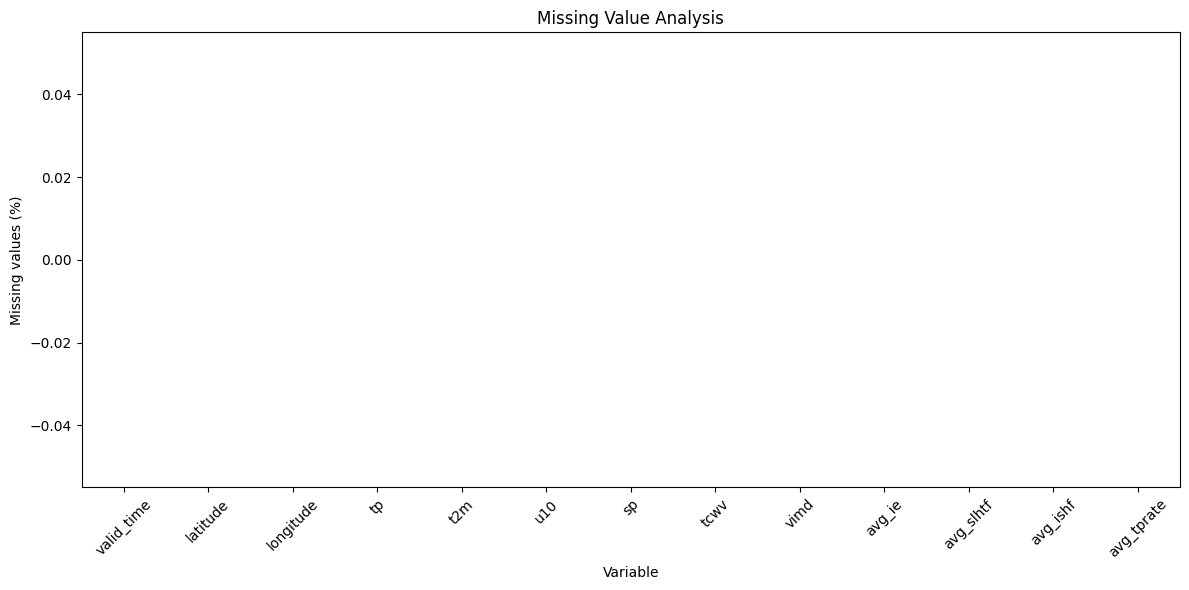

In [ ]:


plt.figure(figsize=(12, 6))

missing_report["missing_percent"].plot(kind="bar")

plt.ylabel("Missing values (%)")
plt.xlabel("Variable")
plt.title("Missing Value Analysis")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:

before = len(model_df)

model_df = model_df.dropna(subset=[target]).copy()

after = len(model_df)

print("Rows before:", before)
print("Rows after :", after)
print("Removed   :", before - after)

Rows before: 702720
Rows after : 702720
Removed   : 0


In [ ]:


model_df = model_df.sort_values(
    ["latitude", "longitude", "valid_time"]
).reset_index(drop=True)

for col in features_present:
    model_df[col] = (
        model_df
        .groupby(["latitude", "longitude"])[col]
        .transform(lambda x: x.interpolate(limit_direction="both"))
    )

print("Remaining missing values:")
print(model_df[features_present + [target]].isnull().sum())

Remaining missing values:
t2m           0
u10           0
sp            0
tcwv          0
vimd          0
avg_ie        0
avg_slhtf     0
avg_ishf      0
avg_tprate    0
tp            0
dtype: int64


In [ ]:
model_df = model_df.dropna(
    subset=features_present + [target]
).reset_index(drop=True)

print("Final cleaned shape:", model_df.shape)

Final cleaned shape: (702720, 13)


In [ ]:

for col in features_present + [target]:

    print("\n", "="*50)
    print(col)

    print("Min :", model_df[col].min())
    print("Max :", model_df[col].max())
    print("Mean:", model_df[col].mean())
    print("Std :", model_df[col].std())


t2m
Min : 290.092529296875
Max : 315.475341796875
Mean: 300.54056
Std : 3.439473867416382

u10
Min : -10.706512451171875
Max : 15.0982666015625
Mean: 3.3376868
Std : 2.1411352157592773

sp
Min : 85587.0625
Max : 101690.0
Mean: 97042.266
Std : 3348.423583984375

tcwv
Min : 17.350692749023438
Max : 77.54539489746094
Mean: 51.809166
Std : 7.840801239013672

vimd
Min : -32.40367126464844
Max : 7.44464111328125
Mean: -0.15273818
Std : 1.085069179534912

avg_ie
Min : -0.00020344601944088936
Max : 1.5665078535676003e-05
Mean: -3.5669163e-05
Std : 3.4363929444225505e-05

avg_slhtf
Min : -508.760009765625
Max : 39.181640625
Mean: -89.2012
Std : 85.93695831298828

avg_ishf
Min : -474.381591796875
Max : 128.75634765625
Mean: -28.614271
Std : 72.44619750976562

avg_tprate
Min : 0.0
Max : 0.007637143135070801
Mean: 8.198348e-05
Std : 0.0002002077380893752

tp
Min : 0.0
Max : 0.02749347686767578
Mean: 0.00029514366
Std : 0.000720571493729949


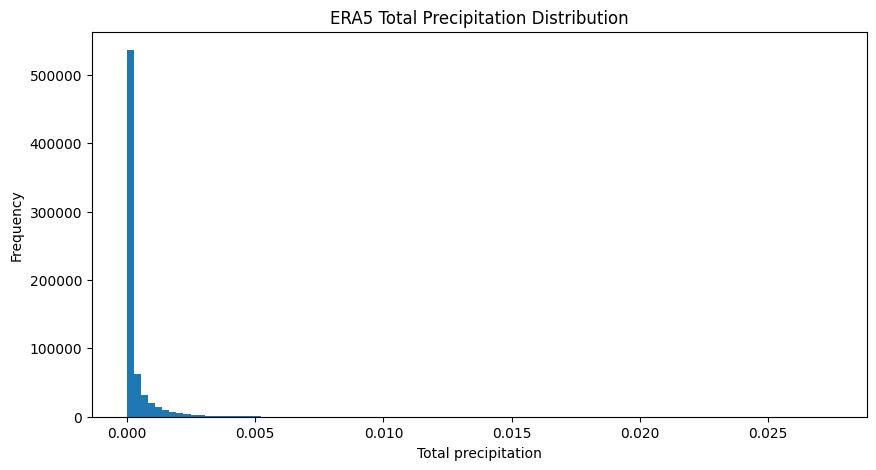

In [ ]:


plt.figure(figsize=(10, 5))

plt.hist(
    model_df["tp"],
    bins=100
)

plt.xlabel("Total precipitation")
plt.ylabel("Frequency")
plt.title("ERA5 Total Precipitation Distribution")

plt.show()

In [ ]:


print(ds["tp"].attrs)

{'GRIB_paramId': np.int64(228), 'GRIB_dataType': 'fc', 'GRIB_numberOfPoints': np.int64(720), 'GRIB_typeOfLevel': 'surface', 'GRIB_stepUnits': np.int64(1), 'GRIB_stepType': 'accum', 'GRIB_gridType': 'regular_ll', 'GRIB_uvRelativeToGrid': np.int64(0), 'GRIB_NV': np.int64(0), 'GRIB_Nx': np.int64(24), 'GRIB_Ny': np.int64(30), 'GRIB_cfName': 'unknown', 'GRIB_cfVarName': 'tp', 'GRIB_gridDefinitionDescription': 'Latitude/Longitude Grid', 'GRIB_iDirectionIncrementInDegrees': np.float64(0.25), 'GRIB_iScansNegatively': np.int64(0), 'GRIB_jDirectionIncrementInDegrees': np.float64(0.25), 'GRIB_jPointsAreConsecutive': np.int64(0), 'GRIB_jScansPositively': np.int64(0), 'GRIB_latitudeOfFirstGridPointInDegrees': np.float64(16.25), 'GRIB_latitudeOfLastGridPointInDegrees': np.float64(9.0), 'GRIB_longitudeOfFirstGridPointInDegrees': np.float64(74.0), 'GRIB_longitudeOfLastGridPointInDegrees': np.float64(79.75), 'GRIB_missingValue': np.float64(3.4028234663852886e+38), 'GRIB_name': 'Total precipitation', 'G

In [ ]:


.
model_df["rain_mm"] = model_df["tp"] * 1000

print(model_df["rain_mm"].describe())

count    702720.000000
mean          0.295144
std           0.720981
min           0.000000
25%           0.000000
50%           0.033379
75%           0.250816
max          27.493477
Name: rain_mm, dtype: float64


In [ ]:
target = "rain_mm"

In [ ]:


model_df["hour"] = model_df["valid_time"].dt.hour
model_df["month"] = model_df["valid_time"].dt.month
model_df["dayofyear"] = model_df["valid_time"].dt.dayofyear


model_df["hour_sin"] = np.sin(
    2 * np.pi * model_df["hour"] / 24
)

model_df["hour_cos"] = np.cos(
    2 * np.pi * model_df["hour"] / 24
)

model_df["month_sin"] = np.sin(
    2 * np.pi * model_df["month"] / 12
)

model_df["month_cos"] = np.cos(
    2 * np.pi * model_df["month"] / 12
)

In [ ]:


model_df = model_df.sort_values(
    ["latitude", "longitude", "valid_time"]
).reset_index(drop=True)

group = model_df.groupby(["latitude", "longitude"])

for lag in [1, 3, 6, 12, 24]:
    model_df[f"rain_lag_{lag}"] = group["rain_mm"].shift(lag)

In [ ]:


for window in [3, 6, 12, 24]:

    model_df[f"rain_roll_mean_{window}"] = (
        group["rain_mm"]
        .transform(lambda x: x.shift(1).rolling(window).mean())
    )

    model_df[f"rain_roll_sum_{window}"] = (
        group["rain_mm"]
        .transform(lambda x: x.shift(1).rolling(window).sum())
    )

In [ ]:

regime_features = [
    c for c in [
        "t2m",
        "u10",
        "sp",
        "tcwv",
        "vimd",
        "avg_ie"
    ]
    if c in model_df.columns
]

print(regime_features)

['t2m', 'u10', 'sp', 'tcwv', 'vimd', 'avg_ie']


In [ ]:

from sklearn.preprocessing import StandardScaler

regime_scaler = StandardScaler()

X_regime = regime_scaler.fit_transform(
    model_df[regime_features]
)

print("Regime matrix:", X_regime.shape)


In [ ]:


from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scores = {}

for k in range(2, 7):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_regime)

    score = silhouette_score(
        X_regime,
        labels
    )

    scores[k] = score

print(scores)

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(scores.keys()),
    list(scores.values()),
    marker="o"
)

plt.xlabel("Number of regimes")
plt.ylabel("Silhouette score")
plt.title("Regime Selection")

plt.show()

In [ ]:
N_REGIMES = max(scores, key=scores.get)

print("Selected regimes:", N_REGIMES)

In [ ]:


kmeans = KMeans(
    n_clusters=N_REGIMES,
    random_state=42,
    n_init=10
)

model_df["regime"] = kmeans.fit_predict(X_regime)

print(
    model_df["regime"].value_counts().sort_index()
)

In [ ]:


regime_summary = (
    model_df
    .groupby("regime")[regime_features + ["rain_mm"]]
    .mean()
)

display(regime_summary)

In [ ]:
plt.figure(figsize=(10, 5))

model_df.boxplot(
    column="rain_mm",
    by="regime"
)

plt.title("Rainfall Distribution by Atmospheric Regime")
plt.suptitle("")
plt.xlabel("Regime")
plt.ylabel("Rainfall (mm)")

plt.show()

In [ ]:


base_features = [
    c for c in [
        "t2m",
        "u10",
        "sp",
        "tcwv",
        "vimd",
        "avg_ie",
        "avg_slhtf",
        "avg_ishf",
        "avg_tprate"
    ]
    if c in model_df.columns
]

time_features = [
    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos"
]

lag_features = [
    c for c in model_df.columns
    if c.startswith("rain_lag_")
    or c.startswith("rain_roll_")
]

feature_columns = (
    base_features
    + time_features
    + lag_features
    + ["regime"]
)

print("Number of features:", len(feature_columns))

print("\nFeatures:")
for f in feature_columns:
    print(f)

In [ ]:


model_df = model_df.dropna(
    subset=feature_columns + ["rain_mm"]
).reset_index(drop=True)

print("Final ML dataset:", model_df.shape)

In [ ]:


unique_times = np.sort(
    model_df["valid_time"].unique()
)

n_times = len(unique_times)

train_end = int(0.70 * n_times)
val_end = int(0.85 * n_times)

train_end_time = unique_times[train_end]
val_end_time = unique_times[val_end]

train_df = model_df[
    model_df["valid_time"] < train_end_time
].copy()

val_df = model_df[
    (model_df["valid_time"] >= train_end_time) &
    (model_df["valid_time"] < val_end_time)
].copy()

test_df = model_df[
    model_df["valid_time"] >= val_end_time
].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nTrain period:")
print(train_df["valid_time"].min(), "to", train_df["valid_time"].max())

print("\nValidation period:")
print(val_df["valid_time"].min(), "to", val_df["valid_time"].max())

print("\nTest period:")
print(test_df["valid_time"].min(), "to", test_df["valid_time"].max())

In [ ]:


X_train = train_df[feature_columns]
y_train = train_df["rain_mm"]

X_val = val_df[feature_columns]
y_val = val_df["rain_mm"]

X_test = test_df[feature_columns]
y_test = test_df["rain_mm"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

In [ ]:


from sklearn.ensemble import RandomForestRegressor

baseline_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

baseline_model.fit(
    X_train.drop(columns=["regime"]),
    y_train
)

baseline_pred = baseline_model.predict(
    X_test.drop(columns=["regime"])
)

print("Baseline model trained.")

In [ ]:


from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_model(y_true, y_pred, name):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    corr = np.corrcoef(
        y_true,
        y_pred
    )[0, 1]

    print("\n", "="*50)
    print(name)
    print("="*50)

    print("MAE  :", mae)
    print("RMSE :", rmse)
    print("R²   :", r2)
    print("Corr :", corr)

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Correlation": corr
    }

baseline_results = evaluate_model(
    y_test,
    baseline_pred,
    "Baseline Random Forest"
)

In [ ]:


regime_model = RandomForestRegressor(
    n_estimators=400,
    max_depth=25,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

regime_model.fit(
    X_train,
    y_train
)

regime_pred = regime_model.predict(
    X_test
)

print("Regime-aware model trained.")

In [ ]:


regime_results = evaluate_model(
    y_test,
    regime_pred,
    "Regime-Aware Random Forest"
)

In [ ]:


results = pd.DataFrame([
    baseline_results,
    regime_results
])

display(results)

In [ ]:


test_results = test_df[
    ["valid_time", "latitude", "longitude", "regime", "rain_mm"]
].copy()

test_results["prediction"] = regime_pred

regime_metrics = []

for regime in sorted(
    test_results["regime"].unique()
):

    subset = test_results[
        test_results["regime"] == regime
    ]

    mae = mean_absolute_error(
        subset["rain_mm"],
        subset["prediction"]
    )

    rmse = np.sqrt(
        mean_squared_error(
            subset["rain_mm"],
            subset["prediction"]
        )
    )

    regime_metrics.append({
        "Regime": regime,
        "Samples": len(subset),
        "MAE": mae,
        "RMSE": rmse
    })

regime_metrics = pd.DataFrame(
    regime_metrics
)

display(regime_metrics)

In [ ]:


importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": regime_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

display(importance)

In [ ]:
plt.figure(figsize=(10, 7))

top_features = importance.head(15)

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top Meteorological Features")

plt.tight_layout()
plt.show()

In [ ]:


plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    regime_pred,
    alpha=0.2
)

max_value = max(
    y_test.max(),
    regime_pred.max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.xlabel("Observed ERA5 Rainfall (mm)")
plt.ylabel("Predicted Rainfall (mm)")
plt.title("Observed vs Regime-Aware Predicted Rainfall")

plt.tight_layout()
plt.show()

In [ ]:


plot_df = test_results.copy()


lat_example = plot_df["latitude"].iloc[0]
lon_example = plot_df["longitude"].iloc[0]

point = plot_df[
    (plot_df["latitude"] == lat_example) &
    (plot_df["longitude"] == lon_example)
].sort_values("valid_time")

plt.figure(figsize=(15, 5))

plt.plot(
    point["valid_time"],
    point["rain_mm"],
    label="Observed"
)

plt.plot(
    point["valid_time"],
    point["prediction"],
    label="Predicted"
)

plt.xlabel("Time")
plt.ylabel("Rainfall (mm)")
plt.title(
    f"Rainfall Prediction at "
    f"{lat_example}°N, {lon_example}°E"
)

plt.legend()
plt.tight_layout()
plt.show()

In [ ]:


import joblib

joblib.dump(
    regime_model,
    "/content/regime_aware_rainfall_model.pkl"
)

joblib.dump(
    regime_scaler,
    "/content/regime_scaler.pkl"
)

joblib.dump(
    kmeans,
    "/content/regime_kmeans.pkl"
)

print("Models saved successfully.")